Dataset Shape: (178, 13)
Number of Features: 13

Explained Variance Ratio:
[0.35792104 0.19270671 0.11019835 0.07272276 0.06721919 0.05131943
 0.04377423 0.02500853 0.0227943  0.01877102 0.01781765 0.01256721
 0.00717958]


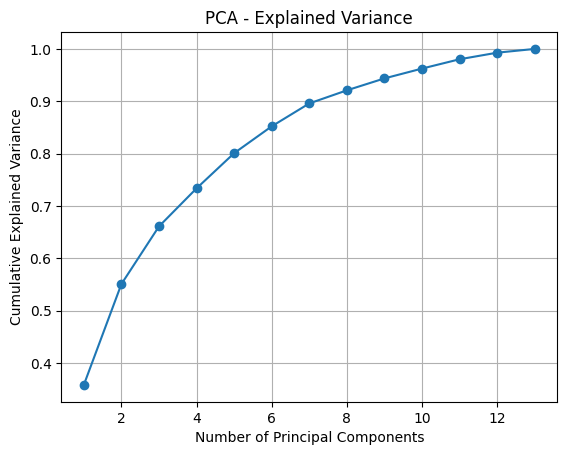


Original Number of Features: 13
Reduced Number of Features: 2
Variance Retained by 2 Components: 0.5506277578733128


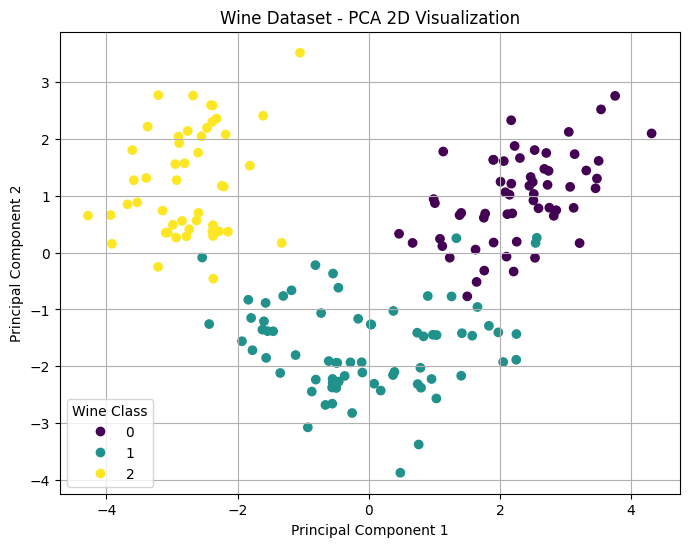


Accuracy Comparison:
Original Data Accuracy: 0.9722222222222222
PCA Reduced Data Accuracy: 0.9166666666666666

Conclusion:
PCA reduces the number of features while retaining important information.


In [1]:
# 1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 2. Load Dataset
wine = load_wine()

X = wine.data
y = wine.target

print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Apply PCA to Analyze Explained Variance
pca_full = PCA()
pca_full.fit(X_train_scaled)

print("\nExplained Variance Ratio:")
print(pca_full.explained_variance_ratio_)

# Plot Cumulative Explained Variance
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_.cumsum(),
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.grid()
plt.show()

# 6. Reduce Dimensions to 2 Components
pca_2 = PCA(n_components=2)

X_train_pca = pca_2.fit_transform(X_train_scaled)
X_test_pca = pca_2.transform(X_test_scaled)

print("\nOriginal Number of Features:", X_train_scaled.shape[1])
print("Reduced Number of Features:", X_train_pca.shape[1])
print("Variance Retained by 2 Components:",
      pca_2.explained_variance_ratio_.sum())

# 7. Visualize Data in 2D
X_all_scaled = scaler.fit_transform(X)
X_all_pca = PCA(n_components=2).fit_transform(X_all_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_all_pca[:, 0],
    X_all_pca[:, 1],
    c=y,
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset - PCA 2D Visualization")
plt.legend(*scatter.legend_elements(), title="Wine Class")
plt.grid()
plt.show()

# 8. Train Model on Original Scaled Data
model1 = LogisticRegression(max_iter=2000)
model1.fit(X_train_scaled, y_train)

y_pred1 = model1.predict(X_test_scaled)
accuracy_original = accuracy_score(y_test, y_pred1)

# 9. Train Model on PCA-Reduced Data
model2 = LogisticRegression(max_iter=2000)
model2.fit(X_train_pca, y_train)

y_pred2 = model2.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, y_pred2)

# 10. Compare Accuracy
print("\nAccuracy Comparison:")
print("Original Data Accuracy:", accuracy_original)
print("PCA Reduced Data Accuracy:", accuracy_pca)

print("\nConclusion:")
print("PCA reduces the number of features while retaining important information.")